# Assignment 09, Problem 3 — Hussein Jawad
**E89 Deep Learning · Speech command recognition with the M5 CNN** (based on Lecture 9 and the class notebook
`lec09_speech_command_recognition.ipynb`)

---

# Problem 3: Training and validation curves for the M5 speech-command model
Start with notebook `lec09_speech_command_recognition.ipynb` described in lecture notes. You need to download the dataset
once. Please disable the cell which lists all labels. Modify the notebook so that at the end of every epoch it uses the
validation data set to determine the accuracy of the current model. Display on the same graph the evolution of the
accuracy on the training and validation set. Display the evolution of the loss on both data sets in another diagram. Use
the test set to evaluate the actual accuracy of the model.

## Approach

### Goal
Train the class notebook's **M5** network (1D convolutions on the raw waveform) to recognize the 35 words of the Speech
Commands dataset, measure loss and accuracy on the **training and validation** sets after every epoch, plot both curves,
and report the accuracy on the **test** set.

### Data (official Speech Commands v0.02 splits)

| Set | Recordings | Used for |
|---|---|---|
| training | 84,843 | updating the weights |
| validation | 9,981 | checking the model after every epoch |
| testing | 11,005 | the final accuracy, used once at the end |

### Steps

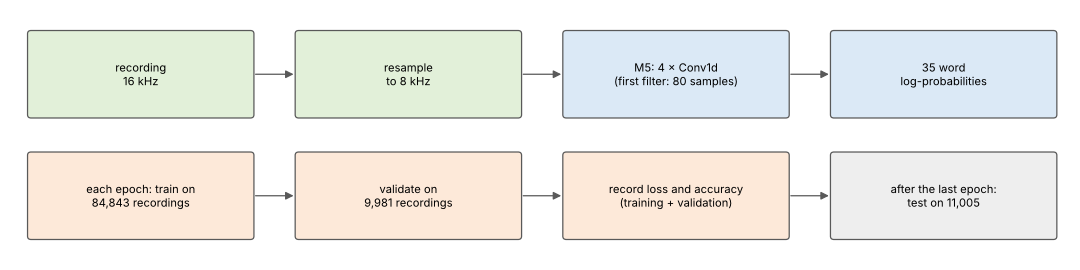

1. **Load** the dataset (downloaded only the first time) and get the 35 labels from the folder names (Steps 2–3).
2. **Batch** the recordings for training, validation and testing (Step 4).
3. **Build** the M5 model and optimizer from the class notebook (Steps 5–6).
4. **Train** for 25 epochs; after each one, record loss and accuracy on the training and validation sets (Steps 7–8).
5. **Plot** both accuracies on one graph and both losses on another (Step 9).
6. **Test** the final model on the test set (Step 10).

### Changes to the class notebook
The class notebook's code is kept; changed or added lines are marked `# NEW` or `# FIX` in the code.
* **Asked by the problem:** the label-listing cell is disabled; `test()` is also used on the validation set after every
  epoch and returns loss and accuracy; `train()` also returns the epoch's training loss and accuracy; the two diagrams.
* **Fixes needed to run correctly with the current libraries:**
  * the training split: the paths in the split lists start with `./` and the dataset's paths do not, so no file was
    excluded and the training set contained all 105,829 recordings, including the validation and test sets.
    `os.path.normpath` makes the paths comparable (training set: 84,843);
  * `torchcodec` is installed (the class notebook has this pip line commented out); without it torchaudio cannot read
    the recordings;
  * `device.type == "cuda"` instead of `device == "cuda"` (a `torch.device` never equals a string).
* **Other:** 25 epochs instead of 2; the training loss is printed every 100 batches instead of 20, without the tqdm
  progress bar; cells not needed for the problem (playing examples, single predictions) are left out.

## Solution

### Step 1: Install torchcodec, imports, versions and device (class notebook)

In [ ]:
%pip install -q torchcodec  # FIX: torchaudio reads the recordings with torchcodec (commented out in the class notebook)

In [ ]:
import torch                                 # PyTorch
import torch.nn as nn                        # neural-network layers
import torch.nn.functional as F              # relu, log_softmax, nll_loss, ...
import torch.optim as optim                  # optimizers and learning-rate schedulers
import torchaudio                            # audio transforms (Resample) and the dataset
import torchcodec                            # decodes the audio files for torchaudio (class notebook)

import matplotlib.pyplot as plt              # plotting

In [ ]:
print("torch: ", torch.__version__)          # PyTorch version
print("torchaudio: ", torchaudio.__version__)  # torchaudio version
print("torchcodec: ", torchcodec.__version__)  # torchcodec version

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # use the GPU when there is one
print(device)                                # cuda or cpu
torch.manual_seed(0)                         # NEW: same initial weights and batch order on every run

### Step 2: The dataset (class notebook, downloaded once)
`download=True` downloads and unpacks the data (about 2.3 GB) only if the folder does not exist yet, so the dataset is
downloaded once.

In [ ]:
from torchaudio.datasets import SPEECHCOMMANDS                    # the Speech Commands dataset
import os                                                         # file paths

class SubsetSC(SPEECHCOMMANDS):                                   # the class notebook's dataset with the official splits
    def __init__(self, subset: str = None):                        # subset = "training", "validation" or "testing"
        super().__init__("./", download=True)                      # downloads and unpacks the data only if not there yet

        def load_list(filename):                                   # reads one of the official split lists
            filepath = os.path.join(self._path, filename)          # e.g. ./SpeechCommands/.../validation_list.txt
            with open(filepath) as fileobj:                        # open the list
                return [os.path.normpath(os.path.join(self._path, line.strip())) for line in fileobj]  # FIX: normpath

        if subset == "validation":                                 # validation files:
            self._walker = load_list("validation_list.txt")        # from the official list
        elif subset == "testing":                                  # test files:
            self._walker = load_list("testing_list.txt")           # from the official list
        elif subset == "training":                                 # training files = all the others
            excludes = load_list("validation_list.txt") + load_list("testing_list.txt")  # files to leave out
            excludes = set(excludes)                               # a set for fast look-up
            self._walker = [w for w in self._walker if os.path.normpath(w) not in excludes]  # FIX: normpath



# Create training, validation and testing splits of the data (the class notebook did not use validation)
train_set = SubsetSC("training")             # training recordings
test_set = SubsetSC("testing")               # test recordings
validation_set = SubsetSC("validation")      # validation recordings (now used after every epoch)

waveform, sample_rate, label, speaker_id, utterance_number = train_set[0]  # the first data point
print("training:", len(train_set), "| validation:", len(validation_set), "| testing:", len(test_set))  # NEW: sizes

### Step 3: The labels (label-listing cell disabled)
The class notebook's cell below reads every training recording just to collect the labels, which takes several minutes.
It is **disabled** (commented out); the labels are the names of the dataset's word folders instead.

In [ ]:
# DISABLED: the class notebook's label-listing cell (it decodes all 84,843 training recordings)
# labels = sorted(list(set(datapoint[2] for datapoint in train_set)))
# labels

In [ ]:
labels = sorted(d for d in os.listdir(train_set._path)          # NEW: the labels are the word-folder names,
                if os.path.isdir(os.path.join(train_set._path, d)) and not d.startswith("_"))  # not _background_noise_
labels                                       # the 35 words

### Step 4: Formatting the data (class notebook) and a validation loader

In [ ]:
new_sample_rate = 8000                       # downsample for faster processing (class notebook)
transform = torchaudio.transforms.Resample(orig_freq=sample_rate, new_freq=new_sample_rate)  # 16 kHz -> 8 kHz
transformed = transform(waveform)            # one resampled example (its shape gives the model's input channels)

In [ ]:
def label_to_index(word):                    # word -> number 0 ... 34
    # Return the position of the word in labels
    return torch.tensor(labels.index(word))  # position of the word in labels

In [ ]:
def pad_sequence(batch):                     # makes all waveforms of a batch the same length
    # Make all tensor in a batch the same length by padding with zeros
    batch = [item.t() for item in batch]     # [samples, 1] for torch's pad_sequence
    batch = torch.nn.utils.rnn.pad_sequence(batch, batch_first=True, padding_value=0.)  # pad with zeros
    return batch.permute(0, 2, 1)            # back to [batch, 1, samples]


def collate_fn(batch):                       # list of data points -> two tensors

    # A data tuple has the form:
    # waveform, sample_rate, label, speaker_id, utterance_number

    tensors, targets = [], []                # waveforms and label numbers

    # Gather in lists, and encode labels as indices
    for waveform, _, label, *_ in batch:     # each data point of the batch
        tensors += [waveform]                # keep the waveform
        targets += [label_to_index(label)]   # and its label number

    # Group the list of tensors into a batched tensor
    tensors = pad_sequence(tensors)          # [batch, 1, samples]
    targets = torch.stack(targets)           # [batch]

    return tensors, targets                  # inputs and labels of the batch


batch_size = 256                             # recordings per batch

if device.type == "cuda":                    # FIX: compare the device type (a torch.device never equals "cuda")
    num_workers = 1                          # one background process loads the data
    pin_memory = True                        # faster copies to the GPU
else:                                        # on the CPU
    num_workers = 0                          # load the data in the main process
    pin_memory = False                       # not needed

train_loader = torch.utils.data.DataLoader(  # training batches
    train_set,                               # from the training set
    batch_size=batch_size,                   # 256 recordings each
    shuffle=True,                            # in random order
    collate_fn=collate_fn,                   # built by collate_fn
    num_workers=num_workers,                 # data-loading processes
    pin_memory=pin_memory,                   # GPU copy setting
)                                            # end of the DataLoader
validation_loader = torch.utils.data.DataLoader(  # NEW: validation batches, like the test loader
    validation_set,                          # from the validation set
    batch_size=batch_size,                   # 256 recordings each
    shuffle=False,                           # in a fixed order
    drop_last=False,                         # keep the last, smaller batch
    collate_fn=collate_fn,                   # built by collate_fn
    num_workers=num_workers,                 # data-loading processes
    pin_memory=pin_memory,                   # GPU copy setting
)                                            # end of the DataLoader
test_loader = torch.utils.data.DataLoader(   # test batches
    test_set,                                # from the test set
    batch_size=batch_size,                   # 256 recordings each
    shuffle=False,                           # in a fixed order
    drop_last=False,                         # keep the last, smaller batch
    collate_fn=collate_fn,                   # built by collate_fn
    num_workers=num_workers,                 # data-loading processes
    pin_memory=pin_memory,                   # GPU copy setting
)                                            # end of the DataLoader

### Step 5: The M5 model (class notebook)

In [ ]:
class M5(nn.Module):                                           # the class notebook's network for raw audio
    def __init__(self, n_input=1, n_output=35, stride=16, n_channel=32):  # 1 audio channel in, 35 words out
        super().__init__()                                     # set up the nn.Module
        self.conv1 = nn.Conv1d(n_input, n_channel, kernel_size=80, stride=stride)  # 80-sample filters (10 ms at 8 kHz)
        self.bn1 = nn.BatchNorm1d(n_channel)                   # normalizes each channel over the batch
        self.pool1 = nn.MaxPool1d(4)                           # keeps the largest of every 4 values
        self.conv2 = nn.Conv1d(n_channel, n_channel, kernel_size=3)       # second convolution
        self.bn2 = nn.BatchNorm1d(n_channel)                   # batch normalization
        self.pool2 = nn.MaxPool1d(4)                           # max pooling
        self.conv3 = nn.Conv1d(n_channel, 2 * n_channel, kernel_size=3)   # third convolution, 64 channels
        self.bn3 = nn.BatchNorm1d(2 * n_channel)               # batch normalization
        self.pool3 = nn.MaxPool1d(4)                           # max pooling
        self.conv4 = nn.Conv1d(2 * n_channel, 2 * n_channel, kernel_size=3)  # fourth convolution
        self.bn4 = nn.BatchNorm1d(2 * n_channel)               # batch normalization
        self.pool4 = nn.MaxPool1d(4)                           # max pooling
        self.fc1 = nn.Linear(2 * n_channel, n_output)          # 64 features -> 35 word scores

    def forward(self, x):                                      # x: [batch, 1, 8000]
        x = self.conv1(x)                                      # block 1: convolution
        x = F.relu(self.bn1(x))                                # batch norm + ReLU
        x = self.pool1(x)                                      # max pooling
        x = self.conv2(x)                                      # block 2
        x = F.relu(self.bn2(x))                                # batch norm + ReLU
        x = self.pool2(x)                                      # max pooling
        x = self.conv3(x)                                      # block 3
        x = F.relu(self.bn3(x))                                # batch norm + ReLU
        x = self.pool3(x)                                      # max pooling
        x = self.conv4(x)                                      # block 4
        x = F.relu(self.bn4(x))                                # batch norm + ReLU
        x = self.pool4(x)                                      # max pooling
        x = F.avg_pool1d(x, x.shape[-1])                       # average over the remaining time steps
        x = x.permute(0, 2, 1)                                 # [batch, 1, 64]
        x = self.fc1(x)                                        # [batch, 1, 35]
        return F.log_softmax(x, dim=2)                         # log-probabilities of the 35 words


model = M5(n_input=transformed.shape[0], n_output=len(labels))  # 1 input channel, 35 outputs
model.to(device)                                               # move the model to the GPU/CPU
print(model)                                                   # show the layers


def count_parameters(model):                                   # number of trainable parameters
    return sum(p.numel() for p in model.parameters() if p.requires_grad)  # add up the sizes of all weights


n = count_parameters(model)                                    # count them
print("Number of parameters: %s" % n)                         # 26,915

### Step 6: Optimizer (class notebook)
Adam with learning rate 0.01 and weight decay 0.0001; the scheduler divides the learning rate by 10 every 20 epochs.

In [ ]:
optimizer = optim.Adam(model.parameters(), lr=0.01, weight_decay=0.0001)  # as in the class notebook
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.1)  # reduce the learning after 20 epochs by a factor of 10

### Step 7: Training and testing functions (class notebook, extended)
`train()` is the class notebook's training loop; it now also returns the epoch's average loss and accuracy (measured on
the training batches while the model learns). `test()` now takes the data set to use (validation or test) and also
returns the loss and the accuracy.

In [ ]:
def train(model, epoch, log_interval):                         # one epoch on the training set
    model.train()                                              # training mode (batch norm uses batch statistics)
    total_loss, correct = 0.0, 0                               # NEW: sums for the epoch's average loss and accuracy
    for batch_idx, (data, target) in enumerate(train_loader):  # one batch at a time

        data = data.to(device)                                 # move the inputs to the GPU/CPU
        target = target.to(device)                             # and the labels

        # apply transform and model on whole batch directly on device
        data = transform(data)                                 # resample to 8 kHz
        output = model(data)                                   # run the model

        # negative log-likelihood for a tensor of size (batch x 1 x n_output)
        loss = F.nll_loss(output.squeeze(), target)            # the loss of this batch

        optimizer.zero_grad()                                  # clear the old gradients
        loss.backward()                                        # backpropagation
        optimizer.step()                                       # update the weights

        # print training stats
        if batch_idx % log_interval == 0:                      # every log_interval batches
            print(f"Train Epoch: {epoch} [{batch_idx * len(data)}/{len(train_loader.dataset)} ({100. * batch_idx / len(train_loader):.0f}%)]\tLoss: {loss.item():.6f}")  # progress

        # record loss
        losses.append(loss.item())                             # loss of every batch (class notebook)
        total_loss += loss.item() * len(target)                # NEW: add up the loss of this batch
        correct += number_of_correct(get_likely_index(output), target)  # NEW: and its correct predictions

    return total_loss / len(train_loader.dataset), correct / len(train_loader.dataset)  # NEW: epoch averages

In [ ]:
def number_of_correct(pred, target):         # number of correct predictions
    # count number of correct predictions
    return pred.squeeze().eq(target).sum().item()  # compare predicted and true labels


def get_likely_index(tensor):                # most likely word for each recording
    # find most likely label index for each element in the batch
    return tensor.argmax(dim=-1)             # index of the largest log-probability


def test(model, epoch, loader=test_loader, name="Test"):       # NEW arguments: which data set, and its name
    model.eval()                                               # evaluation mode (batch norm uses stored statistics)
    correct = 0                                                # correct predictions
    total_loss = 0.0                                           # NEW: summed loss
    with torch.no_grad():                                      # NEW: no gradients needed for evaluation
        for data, target in loader:                            # CHANGED (was test_loader): one batch at a time

            data = data.to(device)                             # move the inputs to the GPU/CPU
            target = target.to(device)                         # and the labels

            # apply transform and model on whole batch directly on device
            data = transform(data)                             # resample to 8 kHz
            output = model(data)                               # run the model

            pred = get_likely_index(output)                    # predicted words
            correct += number_of_correct(pred, target)         # count the correct ones
            total_loss += F.nll_loss(output.squeeze(), target, reduction="sum").item()  # NEW: summed loss

    print(f"{name} Epoch: {epoch}\tAccuracy: {correct}/{len(loader.dataset)} ({100. * correct / len(loader.dataset):.1f}%)\tLoss: {total_loss / len(loader.dataset):.3f}")  # CHANGED: also prints the loss
    return total_loss / len(loader.dataset), correct / len(loader.dataset)  # NEW: average loss and accuracy

### Step 8: Train, validating at the end of every epoch
25 epochs (the class notebook runs 2). After each epoch `test()` is run on the validation set.

In [ ]:
log_interval = 100                           # print the training loss every 100 batches (class notebook: 20)
n_epoch = 25                                 # number of epochs (class notebook: 2)

losses = []                                  # loss of every training batch (class notebook)
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}  # NEW: one value per epoch

# The transform needs to live on the same device as the model and the data.
transform = transform.to(device)             # resampling on the GPU/CPU
for epoch in range(1, n_epoch + 1):          # one epoch at a time
    train_loss, train_acc = train(model, epoch, log_interval)                   # CHANGED: keep the epoch's loss and accuracy
    val_loss, val_acc = test(model, epoch, validation_loader, "Validation")     # NEW: validate the current model
    scheduler.step()                         # learning-rate schedule
    for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):  # NEW: store the four numbers
        history[key].append(value)           # of this epoch

### Step 9: Accuracy and loss curves
Left: accuracy on the training and validation sets on the same graph. Right: the losses in another diagram.

In [ ]:
epochs = range(1, n_epoch + 1)                                 # x axis: epoch numbers
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))                # two diagrams side by side
ax[0].plot(epochs, history["train_acc"], "o-", label="training")      # training accuracy
ax[0].plot(epochs, history["val_acc"], "s-", label="validation")      # validation accuracy
ax[0].set_title("Accuracy")                                    # first diagram: accuracy
ax[0].set_ylabel("accuracy")                                   # vertical axis label
ax[1].plot(epochs, history["train_loss"], "o-", label="training")     # training loss
ax[1].plot(epochs, history["val_loss"], "s-", label="validation")     # validation loss
ax[1].set_title("Loss (negative log-likelihood)")              # second diagram: loss
ax[1].set_ylabel("loss")                                       # vertical axis label
for axis in ax:                                                # common settings
    axis.set_xlabel("epoch")                                   # horizontal axis label
    axis.set_xticks(list(epochs))                              # one tick per epoch
    axis.grid(alpha=0.3)                                       # light grid
    axis.legend()                                              # training vs validation
plt.tight_layout()                                             # avoid overlapping labels
plt.show()                                                     # render the figure

### Step 10: Accuracy on the test set

In [ ]:
test_loss, test_acc = test(model, n_epoch, test_loader, "Test")  # the final model on the 11,005 test recordings

---
# Appendix: The ideas behind Problem 3

## A.1 The M5 network reads the raw waveform
M5 applies 1-D convolutions directly to the audio samples. The 32 filters of the first layer are 80 samples long
(10 ms at 8 kHz) and move 16 samples at a time; each later block (3-sample filters, then max pooling by 4) looks at a
longer stretch of the recording. After the fourth block, averaging leaves 64 numbers per recording, and a linear layer
turns them into 35 word scores (Lecture 9, slides 103–106).

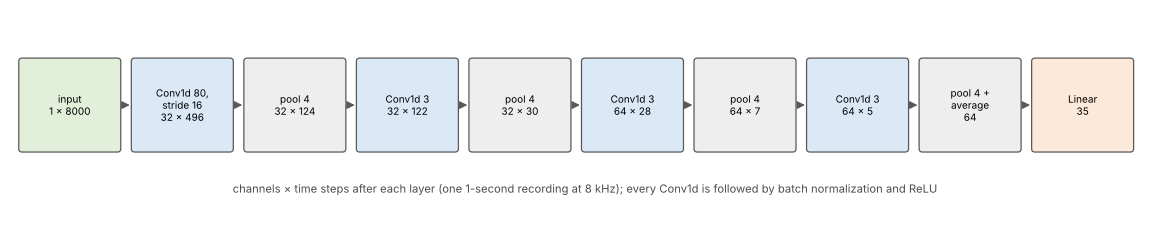

## A.2 Training, validation and test sets
The weights are fitted on the **training** set only. The **validation** set (recordings by other speakers) shows after
every epoch how well the current model works on recordings it has not learned from; the **test** set is used once, at
the end, for the final accuracy. Training accuracy and loss are measured on the training batches while the model is
still changing during the epoch.

When the training and validation curves stay close, the model generalizes; when the validation loss turns up while the
training loss keeps falling, the model starts to memorize the training recordings (overfitting).

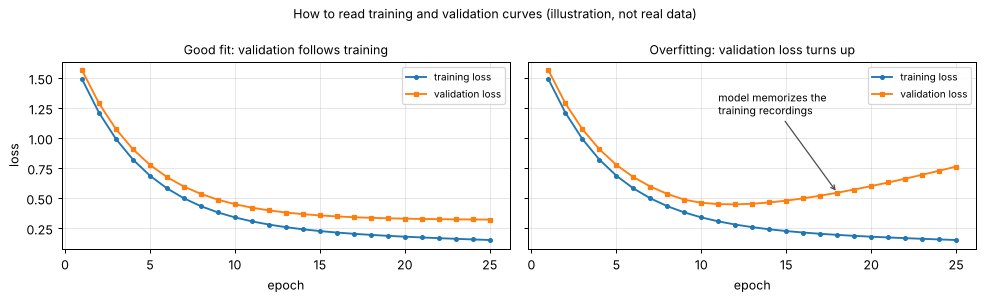

## A.3 The loss
The model outputs log-probabilities $\log p(\text{word})$, and the loss is the negative log-likelihood
$-\log p(\text{correct word})$, averaged over the recordings. A loss of 0 would mean probability 1 for every correct word;
a loss of 0.5 corresponds to an average (geometric mean) probability of $e^{-0.5} \approx 0.61$ for the correct word.